<a href="https://colab.research.google.com/github/longdo9257/longdo9257.github.io/blob/main/Nov4_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

# Direct S3 URL provided
url = 'https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/mc3%2FLUNG_mc3.txt.gz; Full metadata'

try:
    print("Downloading and loading dataset from S3...")
    # pandas can read gzipped tab-separated files directly from a URL
    df = pd.read_csv(url, sep='\t', compression='gzip')
    print(f"Successfully loaded dataset! Shape: {df.shape}")
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Successfully loaded dataset! Shape: (379732, 12)


,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
0,TCGA-05-4244-01,10,101814119,101814119,G,C,CPN1,Missense_Mutation,p.H366D,0.21,deleterious(0),probably_damaging(1)
1,TCGA-05-4244-01,10,129902901,129902901,G,A,MKI67,Silent,p.N2401N,0.04,NaN,NaN
2,TCGA-05-4244-01,10,21104601,21104606,TTACAC,-,NEBL,In_Frame_Del,p.S730_V731del,0.21,NaN,NaN
3,TCGA-05-4244-01,10,45652518,45652518,G,A,RP11-445N18.7,RNA,NaN,0.26,NaN,NaN
4,TCGA-05-4244-01,10,50667200,50667200,G,A,ERCC6,Silent,p.S1381S,0.26,NaN,NaN


In [9]:
TCGA_LUNG_MC3 = df
display(TCGA_LUNG_MC3.head())

,sample,chr,start,end,reference,alt,gene,effect,Amino_Acid_Change,DNA_VAF,SIFT,PolyPhen
0,TCGA-05-4244-01,10,101814119,101814119,G,C,CPN1,Missense_Mutation,p.H366D,0.21,deleterious(0),probably_damaging(1)
1,TCGA-05-4244-01,10,129902901,129902901,G,A,MKI67,Silent,p.N2401N,0.04,NaN,NaN
2,TCGA-05-4244-01,10,21104601,21104606,TTACAC,-,NEBL,In_Frame_Del,p.S730_V731del,0.21,NaN,NaN
3,TCGA-05-4244-01,10,45652518,45652518,G,A,RP11-445N18.7,RNA,NaN,0.26,NaN,NaN
4,TCGA-05-4244-01,10,50667200,50667200,G,A,ERCC6,Silent,p.S1381S,0.26,NaN,NaN


In [10]:
unique_samples_count = TCGA_LUNG_MC3['sample'].nunique()
print(f"Total number of unique samples: {unique_samples_count}")

Total number of unique samples: 993


In [11]:
TCGA_LUNG_MC3.shape

(379732, 12)

In [12]:
# Calculate the number of unique mutated genes in the dataset
unique_genes_count = TCGA_LUNG_MC3['gene'].nunique()
print(f"Total number of unique mutated genes: {unique_genes_count}")

Total number of unique mutated genes: 19434


/tmp/ipykernel_704/3152310783.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')


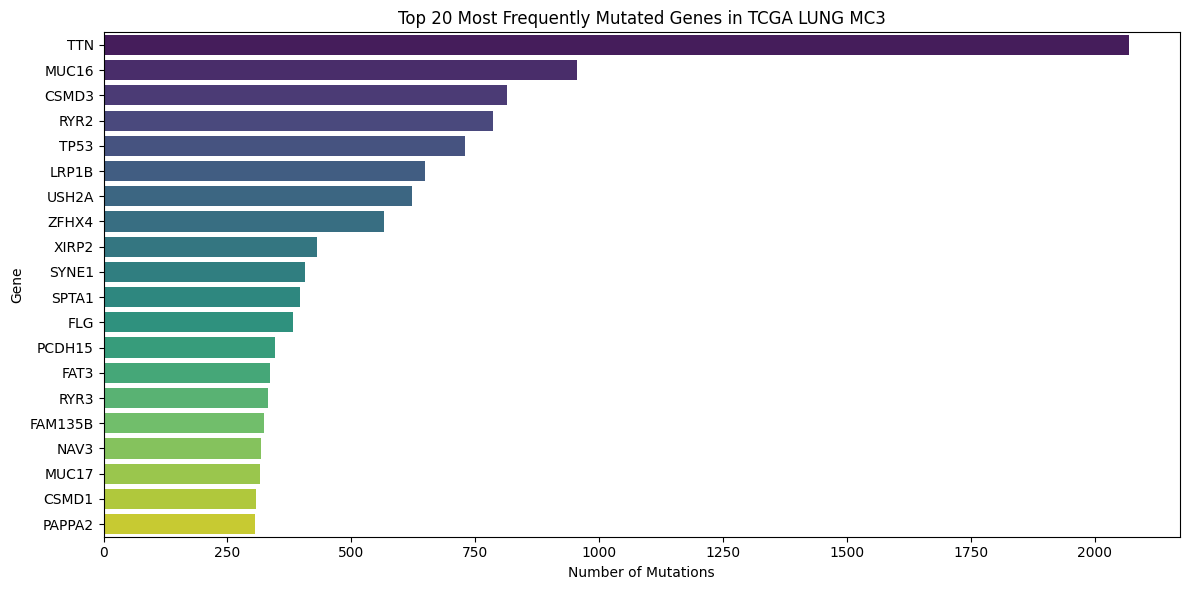

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count mutation frequency per gene
gene_mutation_counts = TCGA_LUNG_MC3['gene'].value_counts().reset_index()
gene_mutation_counts.columns = ['gene', 'mutation_count']

# Get the top 20 most frequently mutated genes
top_20_genes = gene_mutation_counts.head(20)

# Create the plot
plt.figure(figsize=(12, 6))
sns.barplot(data=top_20_genes, x='mutation_count', y='gene', palette='viridis')
plt.title('Top 20 Most Frequently Mutated Genes in TCGA LUNG MC3')
plt.xlabel('Number of Mutations')
plt.ylabel('Gene')
plt.tight_layout()
plt.show()

,mutation_type,count,percentage
0,Missense_Mutation,224474,59.113796
1,Silent,80312,21.149653
2,Nonsense_Mutation,17693,4.659339
3,3'UTR,14227,3.746590
4,Intron,9253,2.436719
5,5'UTR,8219,2.164421
6,Splice_Site,7306,1.923988
7,Frame_Shift_Del,6857,1.805747
8,RNA,5307,1.397565
9,Frame_Shift_Ins,1970,0.518787


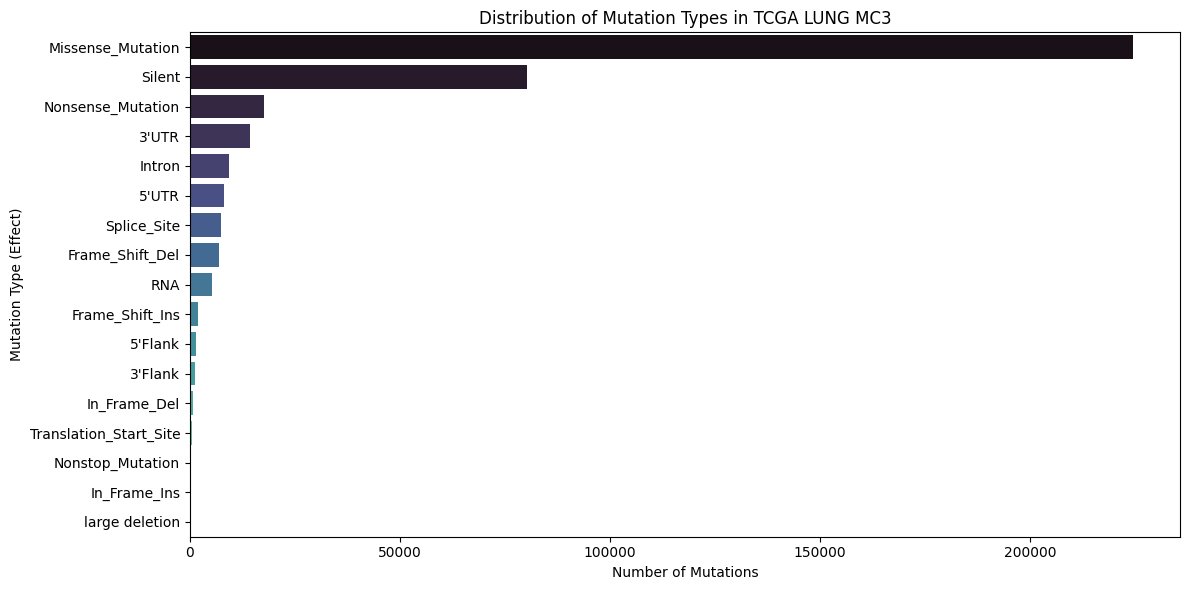

In [14]:
# Calculate the frequency of each mutation effect (type of mutation)
effect_counts = TCGA_LUNG_MC3['effect'].value_counts().reset_index()
effect_counts.columns = ['mutation_type', 'count']
effect_counts['percentage'] = (effect_counts['count'] / effect_counts['count'].sum()) * 100

# Display the mutation types and their frequencies
display(effect_counts)

# Create a visualization of the mutation types
plt.figure(figsize=(12, 6))
sns.barplot(data=effect_counts, x='count', y='mutation_type', hue='mutation_type', legend=False, palette='mako')
plt.title('Distribution of Mutation Types in TCGA LUNG MC3')
plt.xlabel('Number of Mutations')
plt.ylabel('Mutation Type (Effect)')
plt.tight_layout()
plt.show()

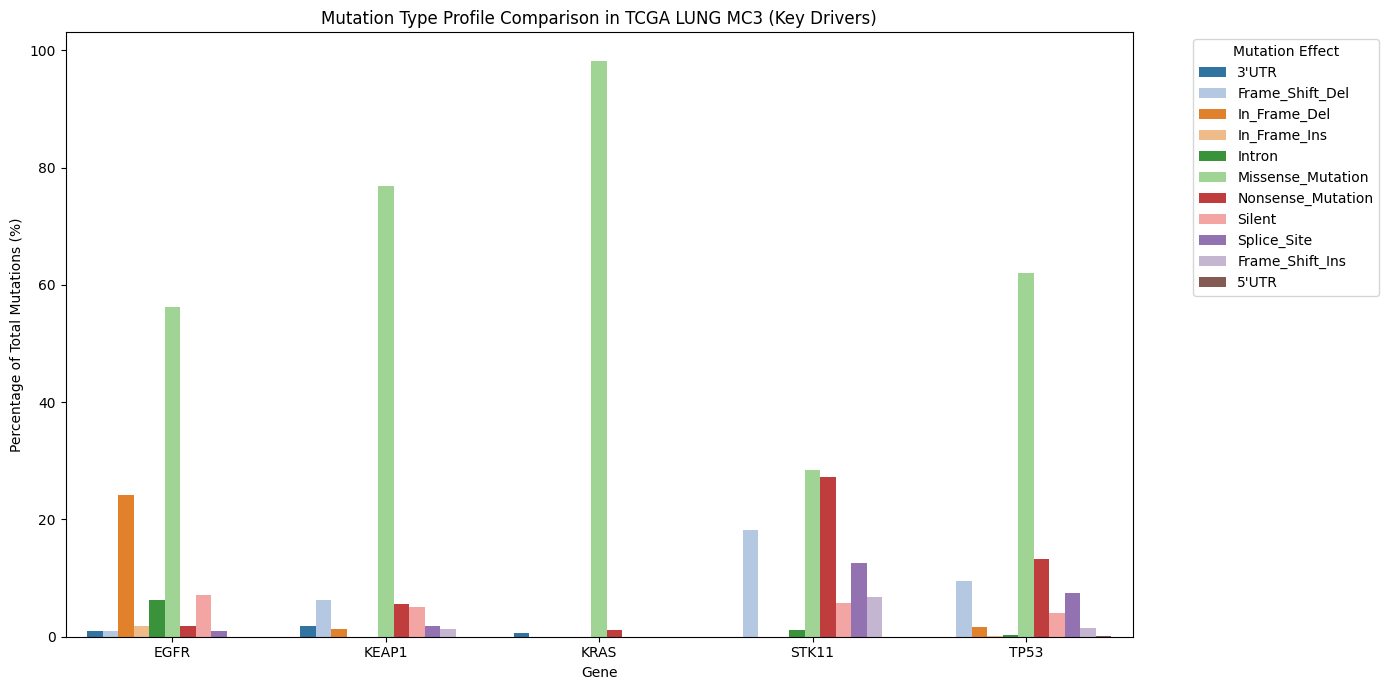

In [15]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Select key lung cancer genes of interest (Oncogenes vs Tumor Suppressors in LUAD/LUSC)
selected_genes = ['TP53', 'KRAS', 'EGFR', 'KEAP1', 'STK11']

# Filter dataset for these genes
df_filtered = TCGA_LUNG_MC3[TCGA_LUNG_MC3['gene'].isin(selected_genes)]

# Calculate counts of each mutation type (effect) per gene
gene_effect_counts = (
    df_filtered.groupby(['gene', 'effect']).size().reset_index(name='count')
)

# Calculate percentages within each gene for fair comparison
gene_totals = df_filtered.groupby('gene').size().reset_index(name='total')
gene_effect_counts = gene_effect_counts.merge(gene_totals, on='gene')
gene_effect_counts['percentage'] = (
    gene_effect_counts['count'] / gene_effect_counts['total']
) * 100

# Plot the comparison
plt.figure(figsize=(14, 7))
sns.barplot(
    data=gene_effect_counts,
    x='gene',
    y='percentage',
    hue='effect',
    palette='tab20',
)

plt.title('Mutation Type Profile Comparison in TCGA LUNG MC3 (Key Drivers)')
plt.xlabel('Gene')
plt.ylabel('Percentage of Total Mutations (%)')
plt.legend(title='Mutation Effect', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [16]:
# Get a list of all unique values in the 'effect' column
unique_effects = TCGA_LUNG_MC3['effect'].value_counts(dropna=False)
print("All unique values in the 'effect' column and their counts:")
display(unique_effects)


All unique values in the 'effect' column and their counts:


,count
effect,
Missense_Mutation,224474
Silent,80312
Nonsense_Mutation,17693
3'UTR,14227
Intron,9253
5'UTR,8219
Splice_Site,7306
Frame_Shift_Del,6857
RNA,5307


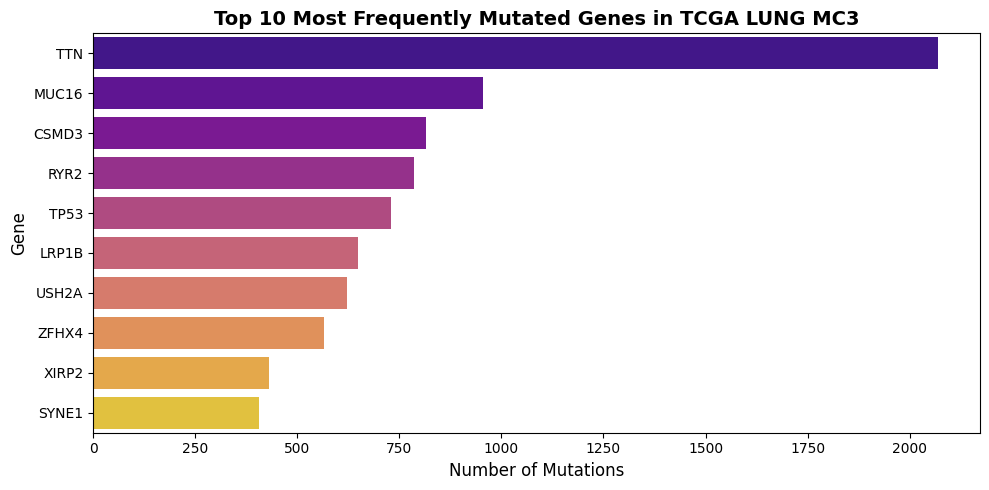

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count mutation frequency per gene
gene_counts = TCGA_LUNG_MC3['gene'].value_counts().reset_index()
gene_counts.columns = ['gene', 'mutation_count']

# Get the top 10 most mutated genes
top_10_genes = gene_counts.head(10)

# Create the visualization
plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_10_genes,
    x='mutation_count',
    y='gene',
    hue='gene',
    legend=False,
    palette='plasma',
)

plt.title(
    'Top 10 Most Frequently Mutated Genes in TCGA LUNG MC3',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Number of Mutations', fontsize=12)
plt.ylabel('Gene', fontsize=12)
plt.tight_layout()
plt.show()